EDA Assignment: Does More Health Spending = Longer Life?
**Name:** ___________________  |  **Date:** __________  |  ⏱️ *Target time: ~1 hour*

---
### 🤔 The big question
Every country spends money on healthcare — some spend *a lot* more than others. It seems obvious that **spending more should mean people live longer**... right?

**Your job:** use EDA to find out if that's actually true. This is an **open-ended** assignment — there's no single "correct" cell to fill in. You explore the data, follow what's interesting, and back up your answer with charts.

> 🎯 **Before you touch the data, write your gut guess here:**
> *Do you think the country that spends the MOST on healthcare also lives the longest? (yes / no / not sure):* __________

**The dataset:** health spending per person vs life expectancy, for 6 wealthy countries, 1970–2020 (real OECD-style data, built into seaborn — loads offline).

### 📤 What to hand in
Answer every ✍️ **question** in your own words, and make sure your charts are clear (titles + labels). Marks reward **insight and evidence**, not fancy code. Run *Kernel → Restart & Run All* before submitting.

## Step 0 — Setup & Load *(warm-up)*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = sns.load_dataset('healthexp')   # Year, Country, Spending_USD, Life_Expectancy
print("Shape:", df.shape)
df.head()

Shape: (274, 4)


,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9


In [2]:
# TODO: Get to know the data. Show:
#   - which countries are included  (HINT: df['Country'].unique())
#   - the range of years            (HINT: df['Year'].min(), df['Year'].max())
#   - a quick df.describe()

print("Countries:", df['Country'].unique())
print("Years:", df['Year'].min(), "to", df['Year'].max())
df.describe()

Countries: <StringArray>
['Germany', 'France', 'Great Britain', 'Japan', 'USA', 'Canada']
Length: 6, dtype: str
Years: 1970 to 2020


,Year,Spending_USD,Life_Expectancy
count,274.000000,274.000000,274.000000
mean,1996.992701,2789.338905,77.909489
std,14.180933,2194.939785,3.276263
min,1970.000000,123.993000,70.600000
25%,1985.250000,1038.357000,75.525000
50%,1998.000000,2295.578000,78.100000
75%,2009.000000,4055.610000,80.575000
max,2020.000000,11859.179000,84.700000


## Task 1 — The Core Relationship *(≈15 min)*
*Is there a link between how much a country spends and how long people live?*

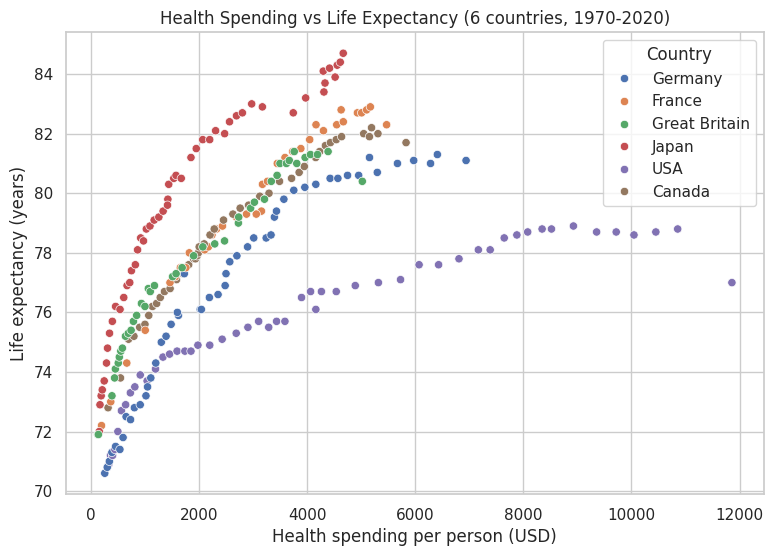

Overall correlation: 0.579


In [3]:
# TODO: Make a scatter plot of Spending_USD (x) vs Life_Expectancy (y).
# Colour the points by Country so you can see who's who.
# HINT: sns.scatterplot(data=df, x='Spending_USD', y='Life_Expectancy', hue='Country')

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='Spending_USD', y='Life_Expectancy', hue='Country')
plt.title('Health Spending vs Life Expectancy (6 countries, 1970-2020)')
plt.xlabel('Health spending per person (USD)')
plt.ylabel('Life expectancy (years)')
plt.show()

print("Overall correlation:", round(df['Spending_USD'].corr(df['Life_Expectancy']), 3))

**✍️ Q1:** In general, as spending goes up, does life expectancy go up, down, or stay flat? Would you call the relationship strong or weak?
*Your answer:* Overall, life expectancy goes **up** as spending goes up, but the relationship is only **moderate**, not strong. The correlation is about 0.58. The scatter plot shows each country rising along its own path, but the countries are spread out vertically, and the USA sits far to the right (high spending) with lower life expectancy than countries that spend much less. So spending is related to life expectancy, but it clearly isn't the whole story.

*Optional hint for evidence:* `df['Spending_USD'].corr(df['Life_Expectancy'])` gives a number from −1 to +1.

## Task 2 — Find the Odd One Out *(≈15 min)*
*Every good analyst looks for what breaks the pattern.*

,Year,Country,Spending_USD,Life_Expectancy
273,2020,USA,11859.179,77.0
269,2020,Germany,6938.983,81.1
268,2020,Canada,5828.324,81.7
270,2020,France,5468.418,82.3
271,2020,Great Britain,5018.700,80.4
272,2020,Japan,4665.641,84.7


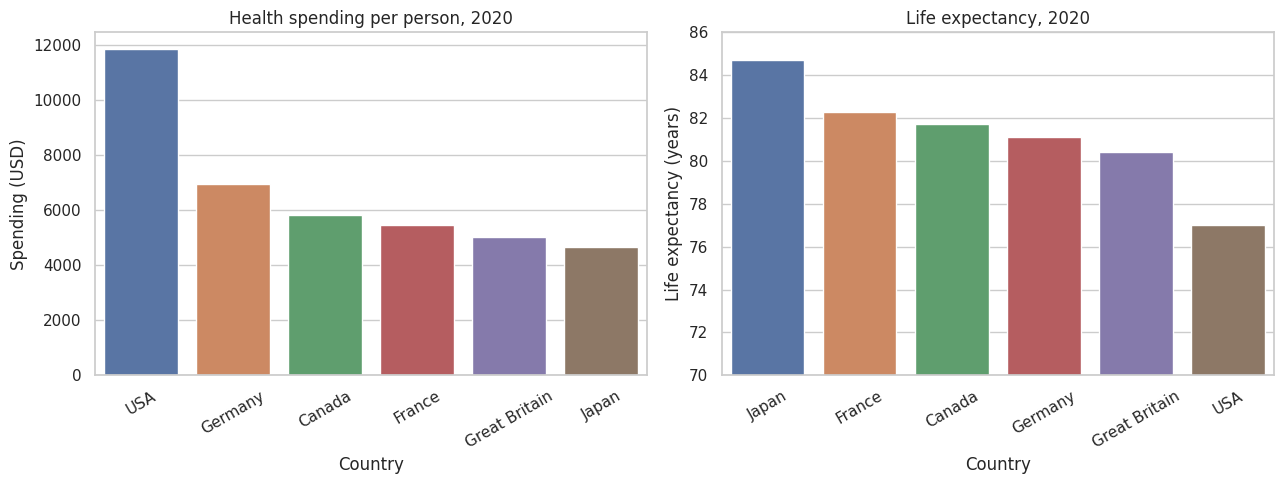

In [4]:
# TODO: Look at just the most recent year in the data.
# HINT: latest = df[df['Year'] == df['Year'].max()]
# Then sort by Spending_USD to see who spends the most vs who lives longest.
# A bar chart of spending per country (for that year) makes it obvious.

latest = df[df['Year'] == df['Year'].max()].sort_values('Spending_USD', ascending=False)
display(latest)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=latest, x='Country', y='Spending_USD', hue='Country', ax=axes[0], legend=False)
axes[0].set_title('Health spending per person, 2020')
axes[0].set_ylabel('Spending (USD)')
latest_le = latest.sort_values('Life_Expectancy', ascending=False)
sns.barplot(data=latest_le, x='Country', y='Life_Expectancy', hue='Country', ax=axes[1], legend=False)
axes[1].set_title('Life expectancy, 2020')
axes[1].set_ylabel('Life expectancy (years)')
axes[1].set_ylim(70, 86)
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**✍️ Q2:** Which country **spends the most** per person? Which country **lives the longest**? Are they the same country? *(This is the heart of the assignment — what surprised you?)*
*Your answer:* In 2020 the **USA spends the most** per person (about $11,859, nearly double most other countries). **Japan lives the longest** (84.7 years) while spending the least of the six (about $4,666). They are **not** the same country. What surprised me is that the USA, the biggest spender, has the *lowest* life expectancy (77.0 years) of all six countries, so more spending clearly doesn't automatically mean longer life.

## Task 3 — Change Over Time *(≈15 min)*
*Has the story always been this way, or did it change?*

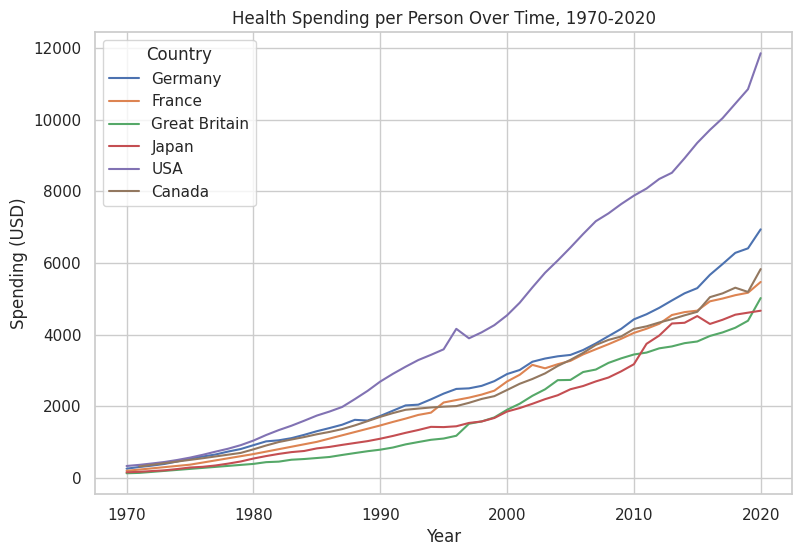

In [5]:
# TODO: Plot how ONE thing changed from 1970 to 2020, for every country.
# Pick either Spending_USD OR Life_Expectancy over Year, with one line per country.
# HINT: sns.lineplot(data=df, x='Year', y='Spending_USD', hue='Country')

plt.figure(figsize=(9, 6))
sns.lineplot(data=df, x='Year', y='Spending_USD', hue='Country')
plt.title('Health Spending per Person Over Time, 1970-2020')
plt.xlabel('Year')
plt.ylabel('Spending (USD)')
plt.show()

**✍️ Q3:** Describe one clear trend you see over time. Does one country pull away from the others at some point?
*Your answer:* All countries' spending rises steadily over 50 years, but the **USA pulls away** from the others starting around the 1980s. By 2020 it spends roughly $11,900 per person, while the other five countries are all between about $4,700 and $6,900. The gap keeps widening over time.

## Task 4 — Your Own Investigation *(≈10 min)*  🔍 *open-ended*
Ask **your own** question about this data and answer it with **one** chart. Ideas (or invent your own):
- Who improved their life expectancy the *most* since 1970?
- Which country gets the most "life expectancy per dollar" (best value)?
- Is any country's life expectancy *flattening* even as spending climbs?

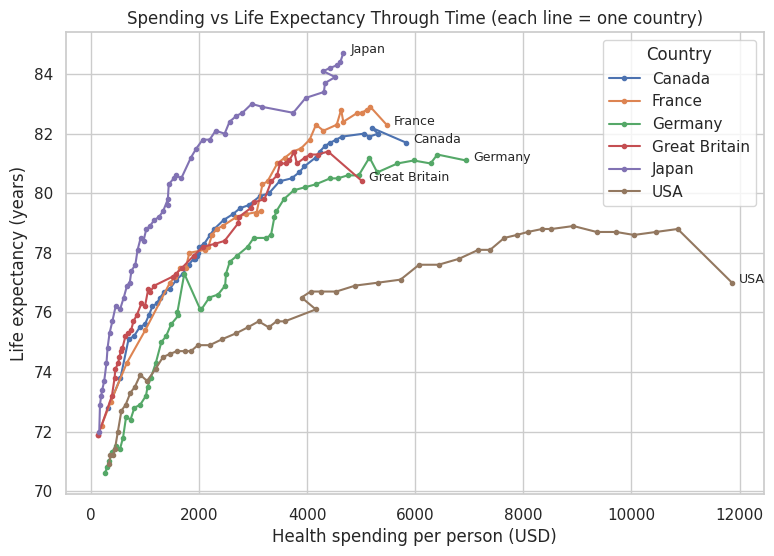

In [6]:
# TODO: Your question, your chart. Write your question as a comment first, then the code.
# My question: Is any country's life expectancy flattening even as spending climbs?
# (Connected scatter: each line follows one country through time, 1970 -> 2020.)

plt.figure(figsize=(9, 6))
for country, d in df.sort_values('Year').groupby('Country'):
    plt.plot(d['Spending_USD'], d['Life_Expectancy'], marker='o', markersize=3, label=country)
    plt.annotate(country, (d['Spending_USD'].iloc[-1], d['Life_Expectancy'].iloc[-1]),
                 textcoords='offset points', xytext=(5, 0), fontsize=9)
plt.title("Spending vs Life Expectancy Through Time (each line = one country)")
plt.xlabel('Health spending per person (USD)')
plt.ylabel('Life expectancy (years)')
plt.legend(title='Country')
plt.show()

**✍️ Q4:** What did *your* chart show? State your finding in one sentence.
*Your answer:* The **USA's** life expectancy has flattened (around 78-79 years since about 2009, then dropping to 77.0 in 2020) even though its spending kept climbing steeply, whereas countries like Japan and France kept gaining years with much lower spending.

## 🏁 Your Verdict
Answer the assignment's big question in **2–3 sentences**, using what your charts showed. Then look back: **was your gut guess from the top right or wrong?**

**✍️ Final verdict:**

> More health spending is loosely associated with longer life (correlation of about 0.58), and within each country life expectancy rose as spending rose. But across countries it is not a guarantee: the USA spends by far the most yet has the lowest life expectancy of the six, while Japan spends the least and lives the longest. So spending alone does not decide how long people live; how the money is used matters too.

> *My original guess was (wrong) because: the country that spends the most (USA) does not live the longest (Japan does), and it actually has the lowest life expectancy of the six.*

---
✅ *Before submitting:* every ✍️ answered, charts have titles/labels, ran Restart & Run All with no errors. Nice work! 🎉